PCA

## Aim

To apply Principal Component Analysis (PCA) to reduce the dimensionality
of selected numerical features in the FRA Atlas dataset while preserving
as much information as possible.

## Dataset Used

The dataset used is `ml/data/labeled_dataset.csv`.

The following numerical features are used for PCA:

- soil_ph
- soil_organic_carbon
- soil_clay_pct
- elevation_m
- groundwater_stress_pct
- rainfall_mm_avg
- land_area_ha

`state` is used only for coloring the final scatter plot.

The following columns are excluded from PCA:
`plot_id`, `lat`, `lon`, `district`, `claim_type`,
`is_scheduled_area`, and all score columns.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA

df = pd.read_csv("../ml/data/labeled_dataset.csv")

features = [
    "soil_ph",
    "soil_organic_carbon",
    "soil_clay_pct",
    "elevation_m",
    "groundwater_stress_pct",
    "rainfall_mm_avg",
    "land_area_ha"
]

X = df[features]

X.head()

,soil_ph,soil_organic_carbon,soil_clay_pct,elevation_m,groundwater_stress_pct,rainfall_mm_avg,land_area_ha
0,7.1,17.22,43.96,667.0,58.0,1150.0,2.63
1,7.4,14.40,46.00,675.0,58.0,1150.0,1.25
2,7.4,14.40,45.10,660.8,58.0,1150.0,3.00
3,7.1,17.22,43.96,666.0,58.0,1150.0,3.59
4,7.1,17.22,43.96,660.8,58.0,1150.0,1.80


## Standardization

PCA is affected by the scale of the variables. Therefore, the selected
features are standardized so that they have comparable scales.

In [2]:
scaler = StandardScaler()

X_scaled = scaler.fit_transform(X)

X_scaled = pd.DataFrame(
    X_scaled,
    columns=features
)

X_scaled.head()

,soil_ph,soil_organic_carbon,soil_clay_pct,elevation_m,groundwater_stress_pct,rainfall_mm_avg,land_area_ha
0,0.892684,-0.435122,1.868063,0.871360,0.934311,-0.348991,0.475584
1,1.346162,-0.788085,2.205303,0.902769,0.934311,-0.348991,-0.782537
2,1.346162,-0.788085,2.056520,0.847018,0.934311,-0.348991,0.812906
3,0.892684,-0.435122,1.868063,0.867434,0.934311,-0.348991,1.350799
4,0.892684,-0.435122,1.868063,0.847018,0.934311,-0.348991,-0.281112


## Apply PCA

PCA transforms the original features into a smaller set of principal
components. Each component captures a portion of the variation present
in the original dataset.

In [3]:
pca = PCA()

X_pca = pca.fit_transform(X_scaled)

print("Original number of features:", X.shape[1])
print("Number of components:", X_pca.shape[1])

Original number of features: 7
Number of components: 7


## Explained Variance Ratio + Scree Plot

In [4]:
explained_variance = pca.explained_variance_ratio_

for i, variance in enumerate(explained_variance, start=1):
    print(f"PC{i}: {variance:.4f}")

PC1: 0.4542
PC2: 0.1966
PC3: 0.1438
PC4: 0.1224
PC5: 0.0493
PC6: 0.0288
PC7: 0.0048


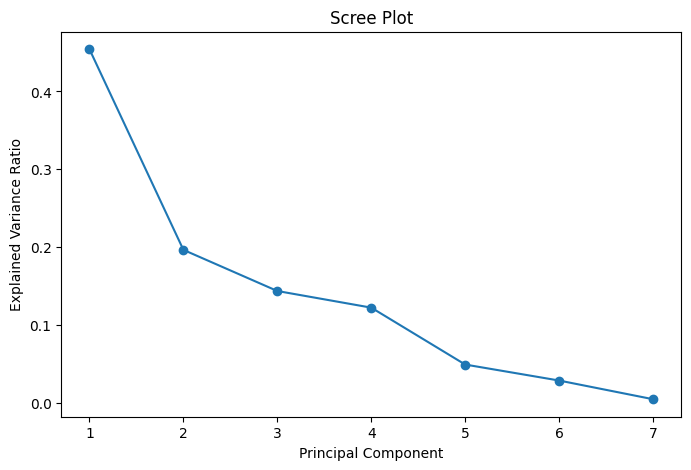

In [5]:
plt.figure(figsize=(8, 5))

plt.plot(
    range(1, len(explained_variance) + 1),
    explained_variance,
    marker="o"
)

plt.xlabel("Principal Component")
plt.ylabel("Explained Variance Ratio")
plt.title("Scree Plot")
plt.xticks(range(1, len(explained_variance) + 1))

plt.show()

## Choose Number of Components

The cumulative explained variance is used to determine how many
principal components should be retained.

In [6]:
cumulative_variance = np.cumsum(explained_variance)

for i, variance in enumerate(cumulative_variance, start=1):
    print(f"First {i} components: {variance:.4f}")

First 1 components: 0.4542
First 2 components: 0.6509
First 3 components: 0.7946
First 4 components: 0.9170
First 5 components: 0.9664
First 6 components: 0.9952
First 7 components: 1.0000


## Transform to 2D & Scatter Plot

The first two principal components are used to represent the dataset
in two dimensions.

The points are colored according to their `state`.

In [7]:
pca_2d = PCA(n_components=2)

X_2d = pca_2d.fit_transform(X_scaled)

pca_df = pd.DataFrame(
    X_2d,
    columns=["PC1", "PC2"]
)

pca_df["state"] = df["state"].values

pca_df.head()

,PC1,PC2,state
0,1.774245,0.916961,Madhya Pradesh
1,2.244939,0.968870,Madhya Pradesh
2,2.223509,0.864566,Madhya Pradesh
3,1.784070,0.893653,Madhya Pradesh
4,1.766978,0.914939,Madhya Pradesh


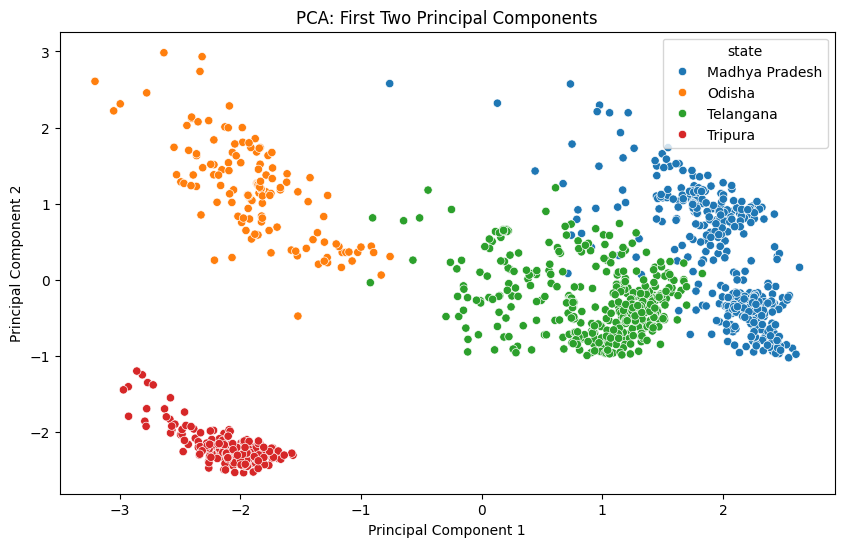

In [8]:
plt.figure(figsize=(10, 6))

sns.scatterplot(
    data=pca_df,
    x="PC1",
    y="PC2",
    hue="state"
)

plt.title("PCA: First Two Principal Components")
plt.xlabel("Principal Component 1")
plt.ylabel("Principal Component 2")

plt.show()

## Component Loadings / Interpretation

Component loadings indicate how strongly each original feature contributes
to each principal component.

In [9]:
loadings = pd.DataFrame(
    pca_2d.components_.T,
    columns=["PC1", "PC2"],
    index=features
)

loadings

,PC1,PC2
soil_ph,0.533133,0.187663
soil_organic_carbon,-0.425396,0.394819
soil_clay_pct,0.278862,0.154380
elevation_m,-0.044253,0.799410
groundwater_stress_pct,0.500834,-0.181741
rainfall_mm_avg,-0.451807,-0.335336
land_area_ha,0.011027,-0.023045


## Conclusion

PCA was applied to the selected standardized numerical features of the
FRA Atlas dataset. The explained variance ratio was used to understand
how much information is captured by each principal component.

The first two principal components were used to visualize the dataset
in two dimensions, with points colored according to their state.
Component loadings were examined to understand the contribution of the
original features to the principal components.